# 📉 Customer Churn Prediction with Logistic Regression
**Binary classification from raw data to threshold tuning and interpretation**

**Objective:** Implement and understand logistic regression for classification: predict which telecom customers will leave (churn).
**Tools:** Scikit-learn, Pandas, Matplotlib (+ NumPy)

**Pipeline**
1. Import & explore the dataset
2. Exploratory analysis of churn drivers
3. Preprocess (clean, encode) and split (stratified)
4. Fit a **logistic regression** model, plus a baseline
5. Evaluate: accuracy, precision, recall, F1, confusion matrix, ROC-AUC, PR curve
6. Tune the **decision threshold** and try **class weights**
7. Interpret the coefficients as **odds ratios**
8. Regularization (`C`), cross-validation and a sample prediction

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, log_loss, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

import warnings
warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
os.makedirs("images", exist_ok=True)   # plots are saved here
RANDOM_STATE = 42
print("✅ Libraries imported")

✅ Libraries imported


## 📥 Step 1: Import & Explore the Dataset

In [2]:
# Auto-detect the churn CSV (works on Kaggle via "+ Add Input" AND locally from the data/ folder)
csv_path = None
for root_dir in ["/kaggle/input", "data"]:
    for dirname, _, filenames in os.walk(root_dir):
        for f in filenames:
            if not f.lower().endswith(".csv"):
                continue
            p = os.path.join(dirname, f)
            try:
                cols = pd.read_csv(p, nrows=1).columns
            except Exception:
                continue
            if {"Churn", "tenure", "MonthlyCharges", "Contract"}.issubset(cols):
                csv_path = csv_path or p

if csv_path is None:
    raise FileNotFoundError("Churn CSV not found. Add the Telco churn dataset on Kaggle or place it in data/.")

print("Using file:", csv_path)
df = pd.read_csv(csv_path)
print("Shape:", df.shape)
df.head()

Using file: data/Telco-Customer-Churn.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Nulls (as NaN):", df.isnull().sum().sum())

# TotalCharges is stored as text: blank strings hide as 'missing' values
blank = df["TotalCharges"].astype(str).str.strip() == ""
print("\nBlank TotalCharges:", blank.sum())
print("Their tenure values:", df.loc[blank, "tenure"].unique(), "-> brand-new customers, nothing billed yet")

Duplicate rows: 0
Nulls (as NaN): 0

Blank TotalCharges: 11
Their tenure values: [0] -> brand-new customers, nothing billed yet


       count     %
Churn             
No      5174  73.5
Yes     1869  26.5


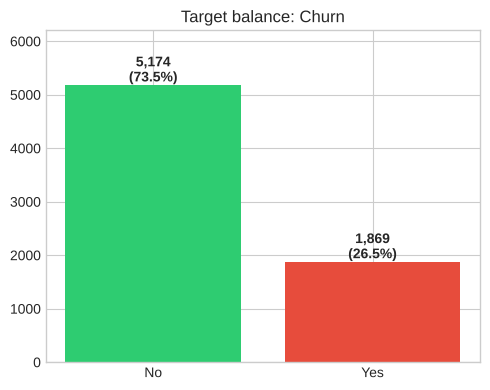

In [5]:
churn_counts = df["Churn"].value_counts()
print(pd.DataFrame({"count": churn_counts, "%": (churn_counts / len(df) * 100).round(1)}))

plt.figure(figsize=(5, 4))
plt.bar(churn_counts.index, churn_counts.values, color=["#2ecc71", "#e74c3c"])
for i, v in enumerate(churn_counts.values):
    plt.text(i, v, f"{v:,}\n({v / len(df) * 100:.1f}%)", ha="center", va="bottom", fontweight="bold")
plt.title("Target balance: Churn"); plt.ylim(0, 6200)
plt.tight_layout()
plt.savefig("images/01_target_balance.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations
- **7,043 customers, 21 columns**, no duplicates
- `TotalCharges` is text with **11 blank values**, all customers with `tenure = 0` (new customers, nothing billed yet) → convert to numeric and fill with **0**
- **Imbalanced target:** 26.5% churned (1,869) vs 73.5% stayed (5,174). A model that always says "stays" is already **73.5% accurate**, so accuracy alone is misleading
- `customerID` is just an identifier and will be dropped

## 🔎 Step 2: What Drives Churn?

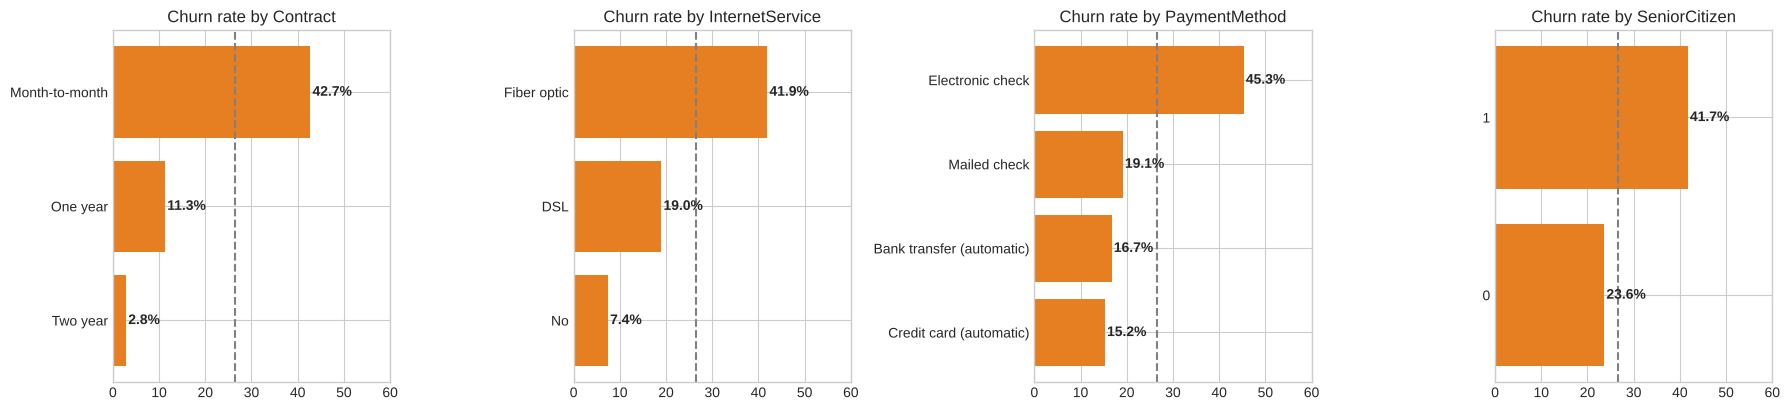

In [6]:
df_eda = df.copy()
df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"].astype(str).str.strip(), errors="coerce").fillna(0)
df_eda["ChurnFlag"] = (df_eda["Churn"] == "Yes").astype(int)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod", "SeniorCitizen"]):
    rate = df_eda.groupby(col)["ChurnFlag"].mean().mul(100).sort_values()
    labels = [str(i) for i in rate.index]
    ax.barh(labels, rate.values, color="#e67e22")
    for i, v in enumerate(rate.values):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontweight="bold")
    ax.axvline(df_eda["ChurnFlag"].mean() * 100, color="gray", linestyle="--")
    ax.set_xlim(0, 60); ax.set_title(f"Churn rate by {col}")
plt.tight_layout()
plt.savefig("images/02_churn_rate_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

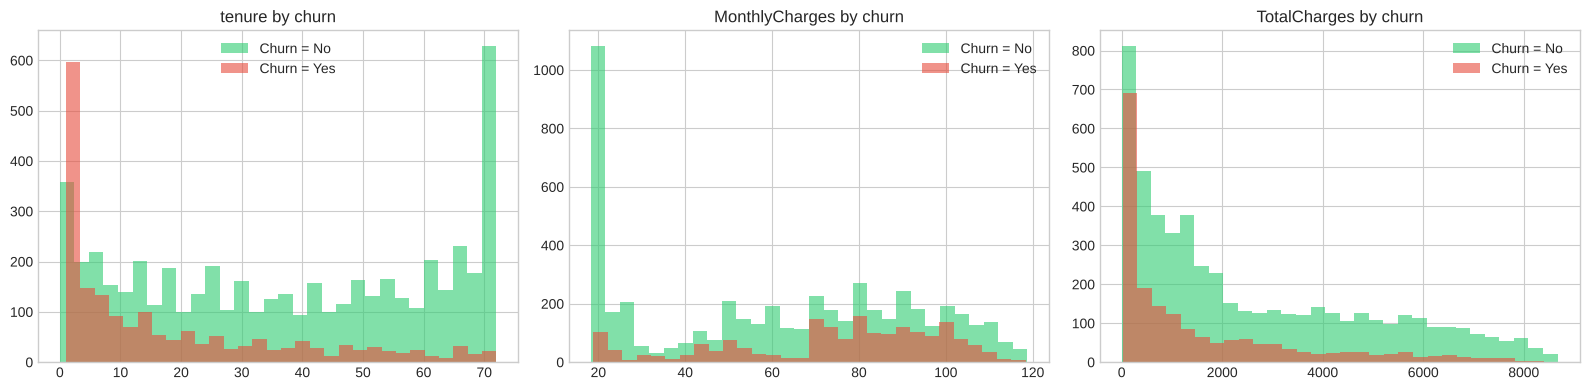

       tenure  MonthlyCharges
Churn                        
No       38.0          64.425
Yes      10.0          79.650


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    for label, color in [("No", "#2ecc71"), ("Yes", "#e74c3c")]:
        ax.hist(df_eda.loc[df_eda["Churn"] == label, col], bins=30, alpha=0.6, color=color, label=f"Churn = {label}")
    ax.set_title(f"{col} by churn"); ax.legend()
plt.tight_layout()
plt.savefig("images/03_numeric_by_churn.png", dpi=150, bbox_inches="tight")
plt.show()

print(df_eda.groupby("Churn")[["tenure", "MonthlyCharges"]].median())

### 📝 Observations (churn drivers)
- **Contract** is the strongest signal: month-to-month **42.7%** churn vs one-year **11.3%** vs two-year **2.8%**
- **Fiber optic** customers churn at **41.9%** vs DSL **19.0%** and no internet **7.4%**
- **Electronic check** payers churn at **45.3%**, versus 15 to 19% for other payment methods
- **Senior citizens** churn more (41.7% vs 23.6%)
- Churners are **new** (median tenure **10** months vs **38**) and pay **more** per month (median **79.65** vs **64.43**)

## 🧹 Step 3: Preprocessing
- `customerID` dropped; `TotalCharges` → numeric (blanks → 0)
- Target `Churn` → 1 (Yes) / 0 (No)
- Binary columns → 1/0; multi-category columns → **one-hot** with `drop_first=True`
- "No internet service" / "No phone service" are merged into **"No"**: they duplicate `InternetService` / `PhoneService`, and keeping them would create perfectly duplicated columns
- **Scaling** (`StandardScaler`) on the 3 numeric columns, fitted on the **training set only** to avoid data leakage. Logistic regression is trained by gradient-based optimisation and regularised, so scaled features matter

In [8]:
data = df.copy()
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"].astype(str).str.strip(), errors="coerce").fillna(0)
data = data.drop(columns="customerID")

data["Churn"] = data["Churn"].map({"Yes": 1, "No": 0})
data["gender"] = data["gender"].map({"Female": 0, "Male": 1})
for c in ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
    data[c] = data[c].map({"Yes": 1, "No": 0})

# merge the redundant "no service" categories into "No"
for c in ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]:
    data[c] = data[c].replace("No internet service", "No")
data["MultipleLines"] = data["MultipleLines"].replace("No phone service", "No")

data = pd.get_dummies(data, drop_first=True, dtype=int)
print("Shape after encoding:", data.shape, "| nulls:", data.isnull().any().any())
data.head()

Shape after encoding: (7043, 24) | nulls: False


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,0,0,0,1,0,1,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0


## ✂️ Step 4: Stratified Train–Test Split, Scaling & Baseline

In [9]:
X = data.drop(columns="Churn")
y = data["Churn"]

# stratify=y keeps the 26.5% churn rate identical in both sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Churn rate  train: {y_train.mean():.3f}  |  test: {y_test.mean():.3f}")

# scale numeric columns (fit on TRAIN only)
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler().fit(X_train[num_cols])
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num_cols] = scaler.transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

# baseline: always predict the majority class ("stays")
dummy = DummyClassifier(strategy="most_frequent").fit(X_train_s, y_train)
print(f"\nBaseline accuracy (always 'No churn'): {accuracy_score(y_test, dummy.predict(X_test_s)):.3f}")

Train: (5634, 23) | Test: (1409, 23)
Churn rate  train: 0.265  |  test: 0.265

Baseline accuracy (always 'No churn'): 0.735


## 📈 Step 5: Fit the Logistic Regression Model
Linear regression predicts any number, but a probability must stay between 0 and 1. Logistic regression passes the linear score
through the **sigmoid** function:

**P(churn) = 1 / (1 + e^−z)**, where **z = b0 + b1·x1 + b2·x2 + ...**

It is trained by minimising **log-loss** (cross-entropy). The class is predicted as 1 when P ≥ 0.5 (the default threshold).

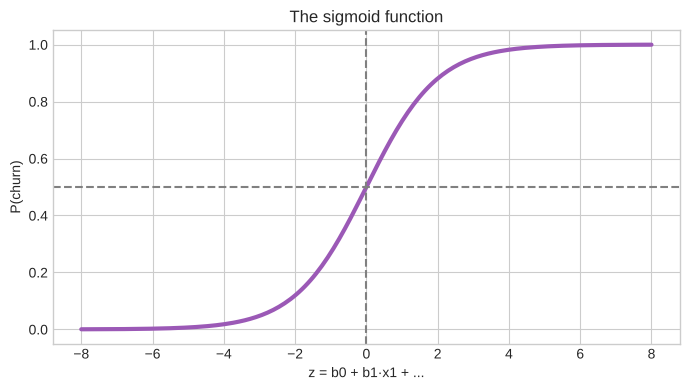

In [10]:
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(7, 4))
plt.plot(z, 1 / (1 + np.exp(-z)), color="#9b59b6", linewidth=3)
plt.axhline(0.5, color="gray", linestyle="--"); plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("z = b0 + b1·x1 + ..."); plt.ylabel("P(churn)")
plt.title("The sigmoid function")
plt.tight_layout()
plt.savefig("images/04_sigmoid.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train_s, y_train)

y_pred = model.predict(X_test_s)               # class labels (threshold 0.5)
y_prob = model.predict_proba(X_test_s)[:, 1]   # probability of churn

print(f"Intercept: {model.intercept_[0]:.3f}")
print("Train accuracy:", round(accuracy_score(y_train, model.predict(X_train_s)), 3),
      "| Test accuracy:", round(accuracy_score(y_test, y_pred), 3))

Intercept: -1.631
Train accuracy: 0.805 | Test accuracy: 0.806


## 🎯 Step 6: Evaluate the Model
Because the data is imbalanced, accuracy is not enough:
- **Precision**: of the customers we flagged as churners, how many really churned?
- **Recall**: of the customers who really churned, how many did we catch?
- **F1**: the balance of precision and recall
- **ROC-AUC**: how well the model **ranks** churners above non-churners, independent of any threshold
- **Log-loss**: how good the predicted probabilities are (lower is better)

In [12]:
metrics = pd.DataFrame({
    "Accuracy":  [accuracy_score(y_test, y_pred)],
    "Precision": [precision_score(y_test, y_pred)],
    "Recall":    [recall_score(y_test, y_pred)],
    "F1":        [f1_score(y_test, y_pred)],
    "ROC-AUC":   [roc_auc_score(y_test, y_prob)],
    "PR-AUC":    [average_precision_score(y_test, y_prob)],
    "Log-loss":  [log_loss(y_test, y_prob)],
}, index=["Logistic Regression (threshold 0.5)"]).round(3)
display(metrics)

print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Log-loss
Logistic Regression (threshold 0.5),0.806,0.658,0.556,0.603,0.842,0.635,0.42


              precision    recall  f1-score   support

      Stayed       0.85      0.90      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



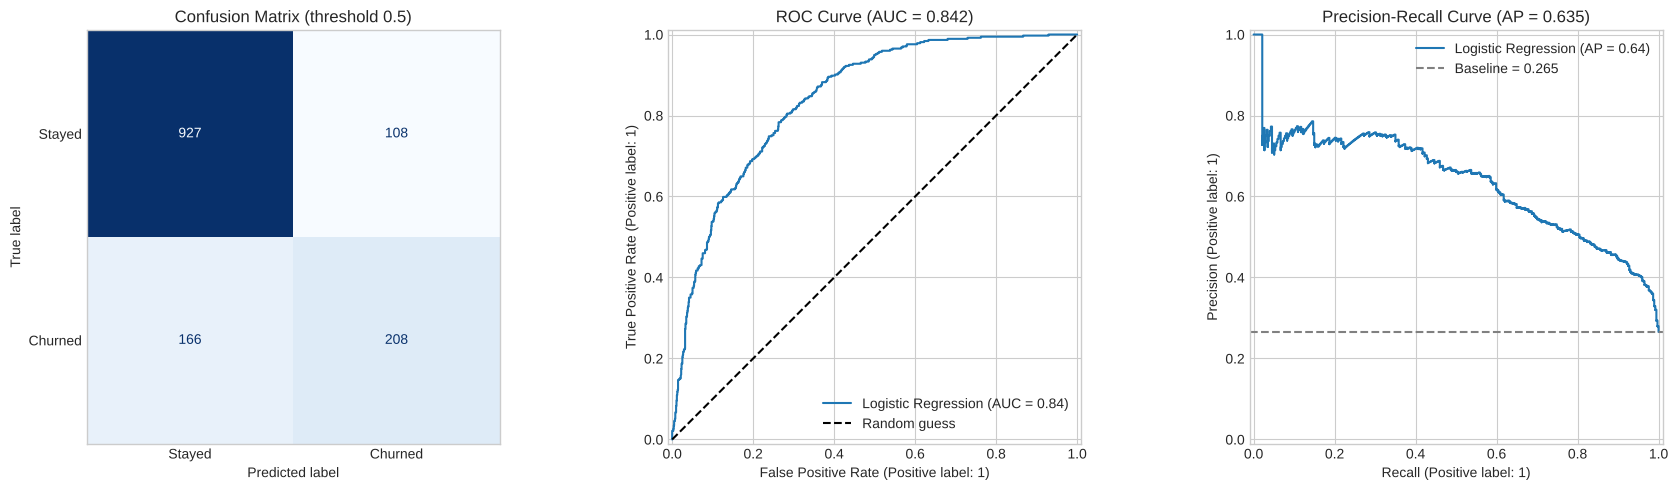

TN = 927  FP = 108  FN = 166  TP = 208


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Stayed", "Churned"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix (threshold 0.5)")
axes[0].grid(False)

RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], name="Logistic Regression")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title(f"ROC Curve (AUC = {roc_auc_score(y_test, y_prob):.3f})"); axes[1].legend()

PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[2], name="Logistic Regression")
axes[2].axhline(y_test.mean(), color="gray", linestyle="--", label=f"Baseline = {y_test.mean():.3f}")
axes[2].set_title(f"Precision-Recall Curve (AP = {average_precision_score(y_test, y_prob):.3f})"); axes[2].legend()

plt.tight_layout()
plt.savefig("images/05_evaluation_curves.png", dpi=150, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"TN = {tn}  FP = {fp}  FN = {fn}  TP = {tp}")

### 📝 Observations (default threshold 0.5)
- **Accuracy 0.806** beats the 0.735 baseline, with train accuracy (0.805) ≈ test accuracy, so **no overfitting**
- **ROC-AUC 0.842**: a randomly chosen churner gets a higher score than a randomly chosen loyal customer 84% of the time
- **Precision 0.658** but **recall only 0.556**: the model **misses 166 of the 374 churners** (false negatives), the costly mistake in a retention setting
- Confusion matrix: TN = 927, FP = 108, FN = 166, TP = 208

## 🎚️ Step 7: Tune the Decision Threshold
0.5 is just a default. Lowering the threshold catches more churners (**higher recall**) at the cost of more false alarms (**lower precision**).
The right choice depends on business cost: contacting a loyal customer is cheap, losing a customer is expensive.

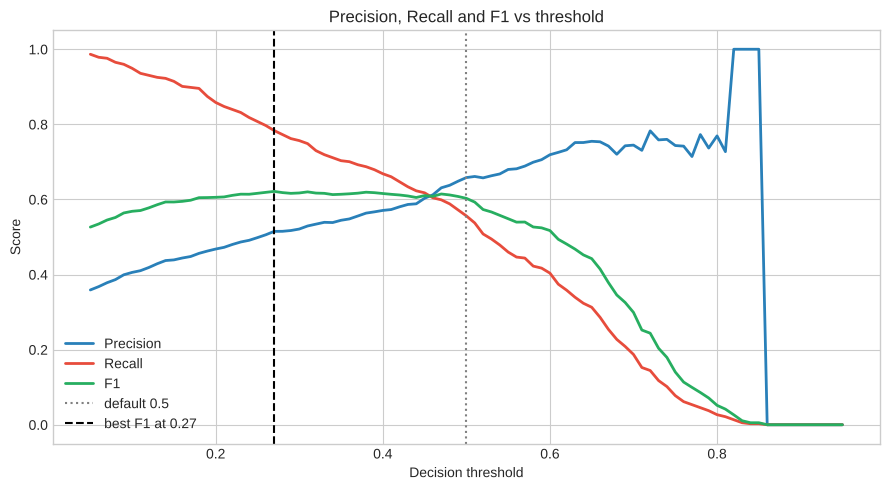

,Accuracy,Precision,Recall,F1,Missed churners (FN),False alarms (FP)
Threshold,,,,,,
0.50,0.806,0.658,0.556,0.603,166,108
0.40,0.779,0.571,0.668,0.616,124,188
0.35,0.765,0.545,0.703,0.614,111,220
0.30,0.751,0.521,0.757,0.617,91,260
0.27,0.747,0.515,0.783,0.621,81,276


In [14]:
thresholds = np.linspace(0.05, 0.95, 91)
prec = [precision_score(y_test, (y_prob >= t).astype(int), zero_division=0) for t in thresholds]
rec  = [recall_score(y_test, (y_prob >= t).astype(int)) for t in thresholds]
f1s  = [f1_score(y_test, (y_prob >= t).astype(int)) for t in thresholds]
best_t = thresholds[int(np.argmax(f1s))]

plt.figure(figsize=(9, 5))
plt.plot(thresholds, prec, label="Precision", color="#2980b9", linewidth=2)
plt.plot(thresholds, rec, label="Recall", color="#e74c3c", linewidth=2)
plt.plot(thresholds, f1s, label="F1", color="#27ae60", linewidth=2)
plt.axvline(0.5, color="gray", linestyle=":", label="default 0.5")
plt.axvline(best_t, color="black", linestyle="--", label=f"best F1 at {best_t:.2f}")
plt.xlabel("Decision threshold"); plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs threshold")
plt.legend()
plt.tight_layout()
plt.savefig("images/06_threshold_tuning.png", dpi=150, bbox_inches="tight")
plt.show()

rows = []
for t in [0.5, 0.4, 0.35, 0.3, round(best_t, 2)]:
    pt = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pt).ravel()
    rows.append({"Threshold": t, "Accuracy": accuracy_score(y_test, pt), "Precision": precision_score(y_test, pt),
                 "Recall": recall_score(y_test, pt), "F1": f1_score(y_test, pt), "Missed churners (FN)": fn, "False alarms (FP)": fp})
pd.DataFrame(rows).round(3).drop_duplicates("Threshold").set_index("Threshold")

### 📝 Observations (threshold)
| Threshold | Precision | Recall | F1 | Comment |
|---|---|---|---|---|
| 0.50 (default) | 0.658 | 0.556 | 0.603 | misses 166 churners |
| 0.40 | 0.571 | 0.668 | 0.616 | better balance |
| 0.35 | 0.545 | 0.703 | 0.614 | catches 70% of churners |
| 0.30 | 0.521 | 0.757 | 0.617 | catches 76% of churners |
| **0.27 (best F1)** | 0.515 | 0.783 | **0.621** | catches 78% of churners |

Lowering the threshold to about **0.30 to 0.35** catches many more churners (recall 0.70 to 0.76) while F1 improves slightly,
at the price of more false alarms and lower accuracy (0.75 to 0.77). The model itself (AUC) does not change, only the decision rule.

## ⚖️ Step 8: Class Weights (`class_weight='balanced'`)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Default (threshold 0.5),0.806,0.658,0.556,0.603,0.842
Tuned threshold (0.30),0.751,0.521,0.757,0.617,0.842
class_weight='balanced',0.740,0.507,0.786,0.616,0.842


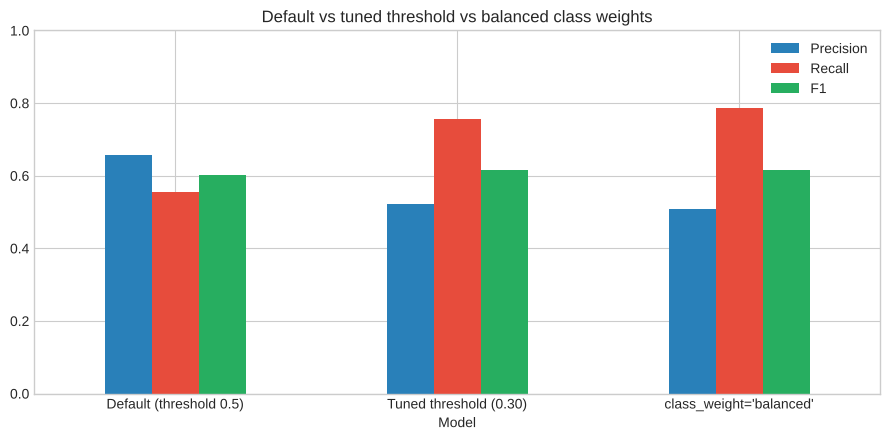

In [15]:
model_bal = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
model_bal.fit(X_train_s, y_train)
pred_bal = model_bal.predict(X_test_s)
prob_bal = model_bal.predict_proba(X_test_s)[:, 1]

def summarize(name, pred, prob):
    return {"Model": name, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, prob)}

pred_t = (y_prob >= 0.30).astype(int)
compare = pd.DataFrame([
    summarize("Default (threshold 0.5)", y_pred, y_prob),
    summarize("Tuned threshold (0.30)", pred_t, y_prob),
    summarize("class_weight='balanced'", pred_bal, prob_bal),
]).set_index("Model").round(3)
display(compare)

ax = compare[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(9, 4.5), color=["#2980b9", "#e74c3c", "#27ae60"], rot=0)
ax.set_title("Default vs tuned threshold vs balanced class weights"); ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig("images/07_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations
- `class_weight='balanced'` gives recall **0.786** (catching 294 of 374 churners) with precision 0.507 and F1 0.616
- Its **ROC-AUC is unchanged (0.842)**: reweighting classes or moving the threshold does not make the model "smarter", it only moves the operating point along the same ROC curve
- Choose the operating point by business cost: if missing a churner is expensive, favour recall

## 🔍 Step 9: Interpret the Coefficients as Odds Ratios
A coefficient is the change in the **log-odds** of churn for a 1-unit increase in a feature (other features constant).
Taking **e^coefficient** gives the **odds ratio**: > 1 raises churn odds, < 1 lowers them.
(Numeric features are standardized, so their odds ratios are *per +1 standard deviation*.)

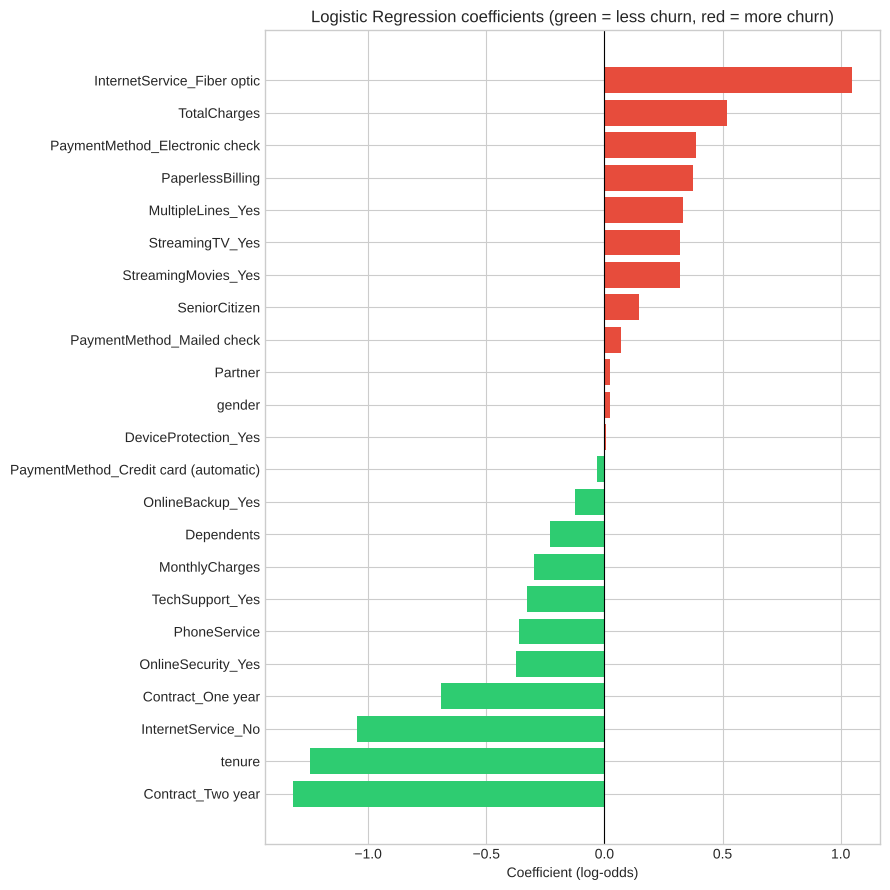

,Coefficient,Odds ratio
InternetService_Fiber optic,1.048,2.853
TotalCharges,0.517,1.678
PaymentMethod_Electronic check,0.386,1.471
PaperlessBilling,0.374,1.454
MultipleLines_Yes,0.335,1.397
StreamingTV_Yes,0.322,1.380
StreamingMovies_Yes,0.322,1.379
SeniorCitizen,0.145,1.156
PaymentMethod_Mailed check,0.072,1.074
Partner,0.024,1.024


In [16]:
coef = pd.Series(model.coef_[0], index=X.columns)
or_df = pd.DataFrame({"Coefficient": coef, "Odds ratio": np.exp(coef)}).sort_values("Coefficient")

plt.figure(figsize=(9, 9))
plt.barh(or_df.index, or_df["Coefficient"], color=["#2ecc71" if v < 0 else "#e74c3c" for v in or_df["Coefficient"]])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression coefficients (green = less churn, red = more churn)")
plt.xlabel("Coefficient (log-odds)")
plt.tight_layout()
plt.savefig("images/08_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

or_df.round(3).sort_values("Odds ratio", ascending=False)

### 📝 Interpretation
| Feature | Odds ratio | Meaning |
|---|---|---|
| `InternetService_Fiber optic` | **2.85** | fiber customers have ~2.9x the churn odds of DSL customers |
| `TotalCharges` | 1.68 | positive here only because it is highly correlated with `tenure` (r = 0.83), so read it together with `tenure` |
| `PaymentMethod_Electronic check` | 1.47 | higher churn risk than bank transfer |
| `PaperlessBilling` | 1.45 | higher churn risk |
| `MultipleLines_Yes` / `StreamingTV_Yes` / `StreamingMovies_Yes` | 1.40 / 1.38 / 1.38 | add-ons tied to higher churn |
| `Contract_Two year` | **0.27** | two-year contract cuts the churn odds by ~73% vs month-to-month |
| `tenure` (+1 std ≈ 24.6 months) | **0.29** | longer relationships sharply reduce churn |
| `InternetService_No` | 0.35 | no internet customers rarely churn |
| `Contract_One year` | 0.50 | halves the churn odds |
| `OnlineSecurity_Yes` / `TechSupport_Yes` | 0.69 / 0.72 | protection and support services reduce churn |

`gender`, `Partner` and `DeviceProtection` have odds ratios ≈ 1.0, so they carry almost no signal.

## 🔁 Step 10: Regularization (`C`) & Cross-Validation

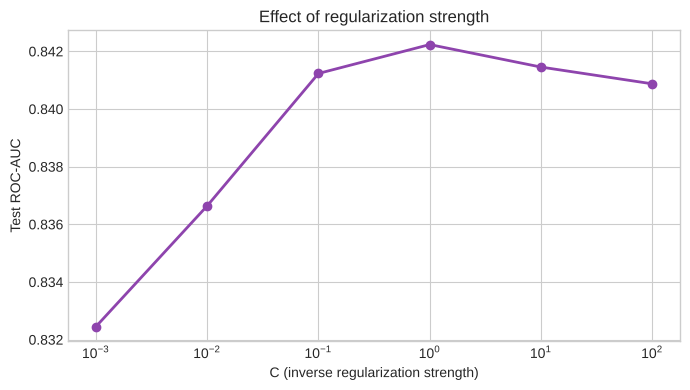

0.001      0.8325
0.010      0.8366
0.100      0.8412
1.000      0.8422
10.000     0.8415
100.000    0.8409
Name: ROC-AUC, dtype: float64


In [17]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
aucs = []
for Cval in C_values:
    m = LogisticRegression(C=Cval, max_iter=2000).fit(X_train_s, y_train)
    aucs.append(roc_auc_score(y_test, m.predict_proba(X_test_s)[:, 1]))

plt.figure(figsize=(7, 4))
plt.semilogx(C_values, aucs, marker="o", color="#8e44ad", linewidth=2)
plt.xlabel("C (inverse regularization strength)"); plt.ylabel("Test ROC-AUC")
plt.title("Effect of regularization strength")
plt.tight_layout()
plt.savefig("images/09_regularization_C.png", dpi=150, bbox_inches="tight")
plt.show()
print(pd.Series(aucs, index=C_values).round(4).rename("ROC-AUC"))

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(LogisticRegression(max_iter=1000), X_train_s, y_train, cv=cv, scoring="roc_auc")

print("ROC-AUC per fold:", np.round(cv_auc, 3))
print(f"Mean ROC-AUC   : {cv_auc.mean():.3f}  (± {cv_auc.std():.3f})")

ROC-AUC per fold: [0.848 0.825 0.842 0.863 0.853]
Mean ROC-AUC   : 0.846  (± 0.013)


### 📝 Observations
- Strong regularization (small `C`) hurts (AUC 0.8325 at `C = 0.001`); performance peaks at **`C = 1`** (the default, AUC **0.8422**) and stays flat for larger values, so the default is already a good choice
- **5-fold stratified CV ROC-AUC = 0.846 (± 0.013)**, consistent with the test AUC of 0.842, so the result is **stable**

## 🏡 Predict a New Customer

In [19]:
new_customer = pd.DataFrame([np.zeros(len(X.columns))], columns=X.columns)
new_customer.loc[0, ["gender", "PhoneService", "PaperlessBilling", "InternetService_Fiber optic",
                     "PaymentMethod_Electronic check"]] = 1
new_customer.loc[0, "tenure"] = 3
new_customer.loc[0, "MonthlyCharges"] = 85
new_customer.loc[0, "TotalCharges"] = 255        # month-to-month contract (no contract dummy set)

new_scaled = new_customer.copy()
new_scaled[num_cols] = scaler.transform(new_customer[num_cols])

p = model.predict_proba(new_scaled)[0, 1]
print(f"Churn probability: {p:.1%}")
print("Decision at threshold 0.30:", "⚠️ likely to churn -> offer retention deal" if p >= 0.30 else "✅ likely to stay")

Churn probability: 66.2%
Decision at threshold 0.30: ⚠️ likely to churn -> offer retention deal


## ✅ Conclusion
- Logistic regression predicts churn with **ROC-AUC ≈ 0.84** (CV 0.846) and **accuracy 0.806**, well above the 0.735 baseline, with no overfitting
- The default 0.5 threshold **misses 44% of churners** (recall 0.556). Lowering it to ~0.30 raises recall to **0.76**, trading precision
- **Month-to-month contracts, fiber optic, short tenure and electronic-check payment** are the biggest churn risks; **long contracts, tenure and security / support services** protect against it
- Next steps: try tree-based models, handle the imbalance with resampling, and add cost-based threshold selection

## 🎤 Interview Questions: Short Answers
1. **Why not use linear regression for classification?** Its output is unbounded (not a probability), it is sensitive to outliers, and thresholding it is unreliable. Logistic regression squashes the score through a sigmoid into (0, 1) and is trained with log-loss.
2. **What is the sigmoid / logit?** Sigmoid: p = 1 / (1 + e^−z). Its inverse, the **logit**, is log(p / (1 − p)) = the log-odds. Logistic regression models the log-odds as a linear function of the features.
3. **How do you interpret coefficients?** A coefficient is the change in log-odds per 1-unit increase in the feature. **e^coef** is the odds ratio (> 1 raises the event's odds, < 1 lowers them).
4. **Precision vs recall?** Precision = TP / (TP + FP) (how many flagged are real). Recall = TP / (TP + FN) (how many real ones were caught). Favour recall when misses are costly (churn, fraud, disease) and precision when false alarms are costly.
5. **What is ROC-AUC?** The area under the TPR-vs-FPR curve: the probability that a random positive is ranked above a random negative. 0.5 is random, 1.0 is perfect. It is threshold-independent. On heavily imbalanced data, also check PR-AUC.
6. **Why is accuracy misleading here?** With 73.5% non-churners, always predicting "stays" scores 73.5%. Use precision, recall, F1, ROC/PR-AUC.
7. **How do you choose the threshold?** Plot precision/recall/F1 against the threshold and pick the point that matches business costs (e.g. cost of a missed churner vs a wasted retention offer), ideally on validation data.
8. **Role of regularization?** The penalty (L2/L1) shrinks coefficients to reduce overfitting. In scikit-learn, **C = 1 / λ**: smaller C means stronger regularization. L1 can drive coefficients to exactly 0 (feature selection).
9. **How do you handle imbalanced classes?** Stratified splits, `class_weight='balanced'`, resampling (SMOTE / undersampling), threshold tuning, and metrics such as F1, PR-AUC and recall.
10. **Assumptions of logistic regression?** Binary (or properly encoded) target, independent observations, a linear relationship between features and the **log-odds**, little multicollinearity and enough samples. It does not require normally distributed features or residuals.
11. **Can it handle more than two classes?** Yes: one-vs-rest, or multinomial (softmax) regression.